In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
sales = pd.read_csv("python_project.csv")
sales.head()

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Customer_Age,City,State,Region,Product_ID,Product_Name,Category,Unit_Price_NGN,Quantity,Discount,Payment_Method,Sales_Channel,Order_Status,Sales_NGN,Profit_NGN
0,ORD00001,22/05/2024,28/05/2024 19:00,CUST0280,Chidi Ojo,45.0,Akure,Ondo,South West,P001,Wireless Mouse,Electronics,8500,5,0,ussd,Phone Order,Returned,42500,14450
1,ORD00002,19 July 2025,24/07/2025,CUST0036,Bola Balogun,32.0,Bauchi,Bauchi,North East,P002,USB Keyboard,Electronics,12500,10,0.05,Cash,Phone Order,Delivered,118750,32953.12
2,ORD00003,01/10/2024 09:15,06 October 2024,CUST0162,Grace Balogun,49.0,Benin City,Edo,South South,P014,External Hard Drive,Electronics,68000,1,0,WALLET,Phone Order,Returned,68000,14960
3,ORD00004,27 April 2024,2024-05-04,CUST0175,Dami Eze,45.0,BAUCHI,Bauchi,North East,P014,External Hard Drive,Electronics,68000,10,0.1,NaN,In-store,Returned,612000,94860
4,ORD00005,28/03/2024,04/04/2024,CUST0273,Emeka Bello,60.0,Ibadan,Oyo,South West,P004,Phone Charger,Accessories,6500,6,0.2,Bank Transfer,PHONE ORDER,Delivered,31200,4680


In [9]:
# Make a copy of the original dataset
sales = sales.copy()

# Remove duplicate records
sales = sales.drop_duplicates()

# Remove extra spaces and standardise text columns
text_columns = [
    "Customer_Name", "City", "State", "Region",
    "Product_Name", "Category", "Payment_Method",
    "Sales_Channel", "Order_Status"
]

for col in text_columns:
    sales[col] = sales[col].astype("string").str.strip().str.title()

# Standardise category names
sales["Category"] = sales["Category"].replace({
    "Electronic": "Electronics",
    "Stationary": "Stationery",
    "Furnitures": "Furniture",
    "Life Style": "Lifestyle"
})

# Standardise region names
sales["Region"] = sales["Region"].replace({
    "Northeast": "North East",
    "Northwest": "North West",
    "Northcentral": "North Central",
    "Southwest": "South West",
    "Southeast": "South East",
    "Southsouth": "South South"
})

# Clean date columns
sales["Order_Date"] = pd.to_datetime(
    sales["Order_Date"], errors="coerce", dayfirst=True, format="mixed"
)

sales["Ship_Date"] = pd.to_datetime(
    sales["Ship_Date"], errors="coerce", dayfirst=True, format="mixed"
)

# Clean numeric columns
numeric_columns = [
    "Customer_Age", "Unit_Price_NGN", "Quantity",
    "Discount", "Sales_NGN", "Profit_NGN"
]

for col in numeric_columns:
    sales[col] = (
        sales[col].astype("string")
        .str.replace("₦", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.replace("%", "", regex=False)
        .str.strip()
    )
    sales[col] = pd.to_numeric(sales[col], errors="coerce")

# Convert percentage discounts to decimal values
sales.loc[sales["Discount"] > 1, "Discount"] = (
    sales.loc[sales["Discount"] > 1, "Discount"] / 100
)

# Remove invalid ages
sales.loc[~sales["Customer_Age"].between(18, 100), "Customer_Age"] = np.nan

# Remove invalid quantities
sales.loc[sales["Quantity"] <= 0, "Quantity"] = np.nan

# Remove invalid discounts
sales.loc[~sales["Discount"].between(0, 1), "Discount"] = np.nan

# Remove records without essential information
sales = sales.dropna(subset=[
    "Order_ID", "Order_Date", "Category",
    "Sales_NGN", "Profit_NGN"
])

# Create additional columns
sales["Month"] = sales["Order_Date"].dt.month_name()
sales["Year"] = sales["Order_Date"].dt.year
sales["Month_Year"] = sales["Order_Date"].dt.to_period("M").astype(str)

# Check cleaned data
print(sales.info())
print(sales.isnull().sum())

# Verify standardised categories and regions
print("\nCategories:")
print(sales["Category"].value_counts())

print("\nRegions:")
print(sales["Region"].value_counts())

<class 'pandas.DataFrame'>
Index: 1157 entries, 0 to 1199
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order_ID        1157 non-null   str           
 1   Order_Date      1157 non-null   datetime64[us]
 2   Ship_Date       969 non-null    datetime64[us]
 3   Customer_ID     1157 non-null   str           
 4   Customer_Name   1136 non-null   string        
 5   Customer_Age    1140 non-null   Float64       
 6   City            1148 non-null   string        
 7   State           1157 non-null   string        
 8   Region          1157 non-null   string        
 9   Product_ID      1157 non-null   str           
 10  Product_Name    1149 non-null   string        
 11  Category        1157 non-null   string        
 12  Unit_Price_NGN  1129 non-null   Int64         
 13  Quantity        1152 non-null   Int64         
 14  Discount        1151 non-null   Float64       
 15  Payment_Method  1145

   Month_Year  Sales_NGN
0     2024-01    2786825
1     2024-02    3820880
2     2024-03    4914620
3     2024-04    3902440
4     2024-05    3658775
5     2024-06    4744790
6     2024-07    3851190
7     2024-08    3904600
8     2024-09    4229420
9     2024-10    5399670
10    2024-11    5459925
11    2024-12    6760030
12    2025-01    5082515
13    2025-02    6136015
14    2025-03    3909490
15    2025-04    4679600
16    2025-05    3382220
17    2025-06    4741845
18    2025-07    2032030
19    2025-08    5247150
20    2025-09    3852540
21    2025-10    6150600
22    2025-11    5502840
23    2025-12    4116775


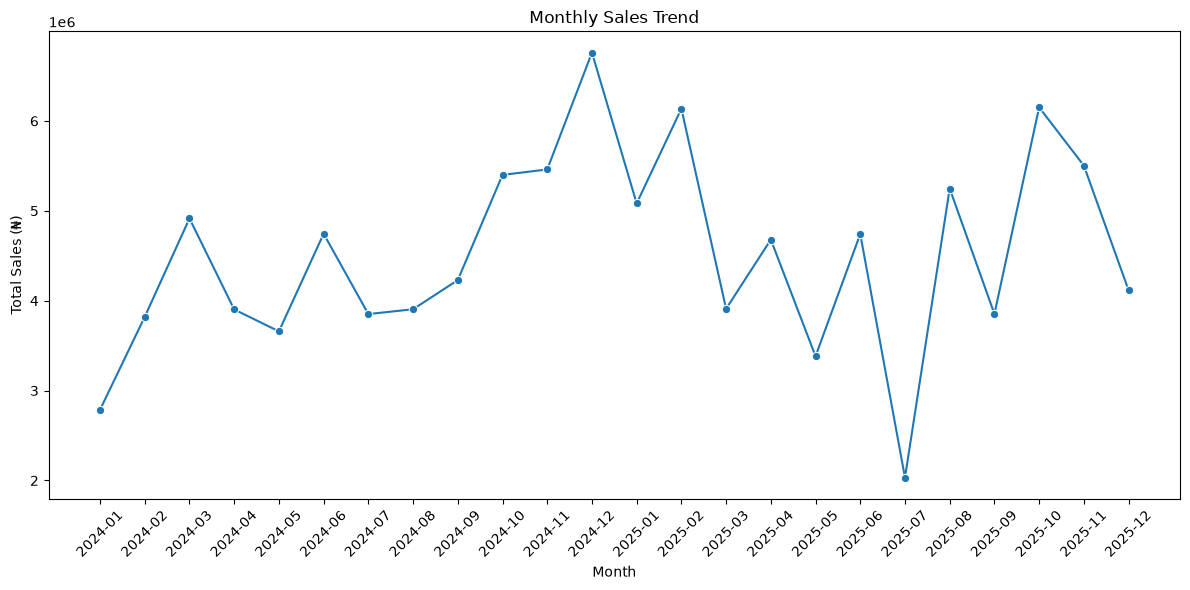

In [4]:
#How did sales chnage overtime
# Calculate monthly sales
monthly_sales = sales.groupby("Month_Year")["Sales_NGN"].sum().reset_index()

# Sort by month
monthly_sales = monthly_sales.sort_values("Month_Year")

# Display results
print(monthly_sales)

# Create line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales,
    x="Month_Year",
    y="Sales_NGN",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (₦)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

      Category  Sales_NGN
0    Furniture   56369100
1  Electronics   34635250
2  Accessories    7042675
3    Lifestyle    6912025
4   Stationery    3307735


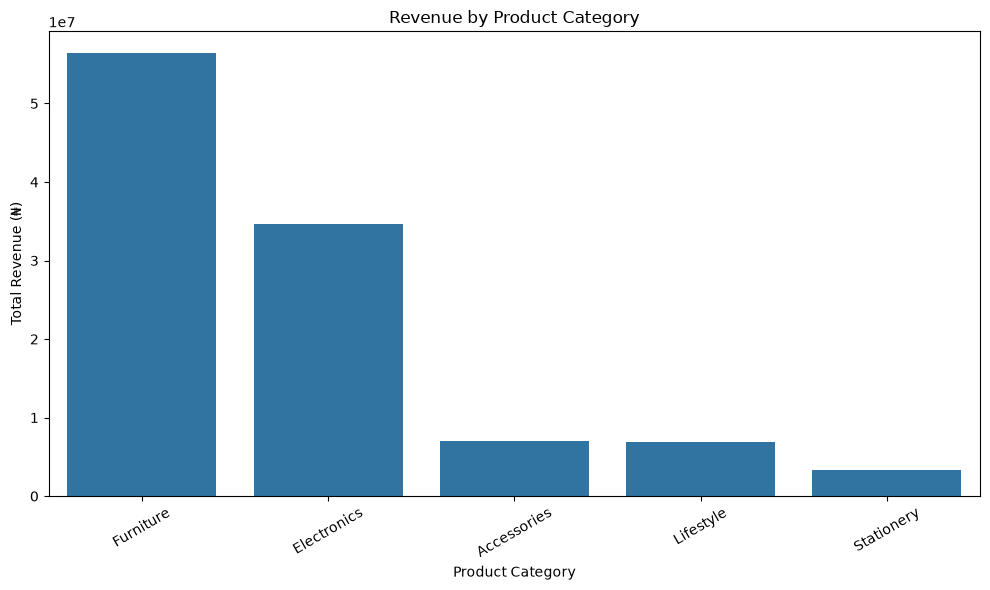

In [5]:
# Which product category generates the highest reveune
# Calculate revenue by category
category_sales = (
    sales.groupby("Category")["Sales_NGN"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print(category_sales)

# Create bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_sales,
    x="Category",
    y="Sales_NGN"
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue (₦)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

   Customer_Name  Sales_NGN
0    Luka Okafor    2027960
1   Mariam Bello    1907180
2   Bola Balogun    1610260
3   Ifeoma Bello    1493800
4      Dami Umar    1438315
5   Rita Adebayo    1346270
6  Chidi Adebayo    1299700
7      Emeka Ojo    1285000
8   Uche Ibrahim    1268560
9      Grace Ojo    1150975


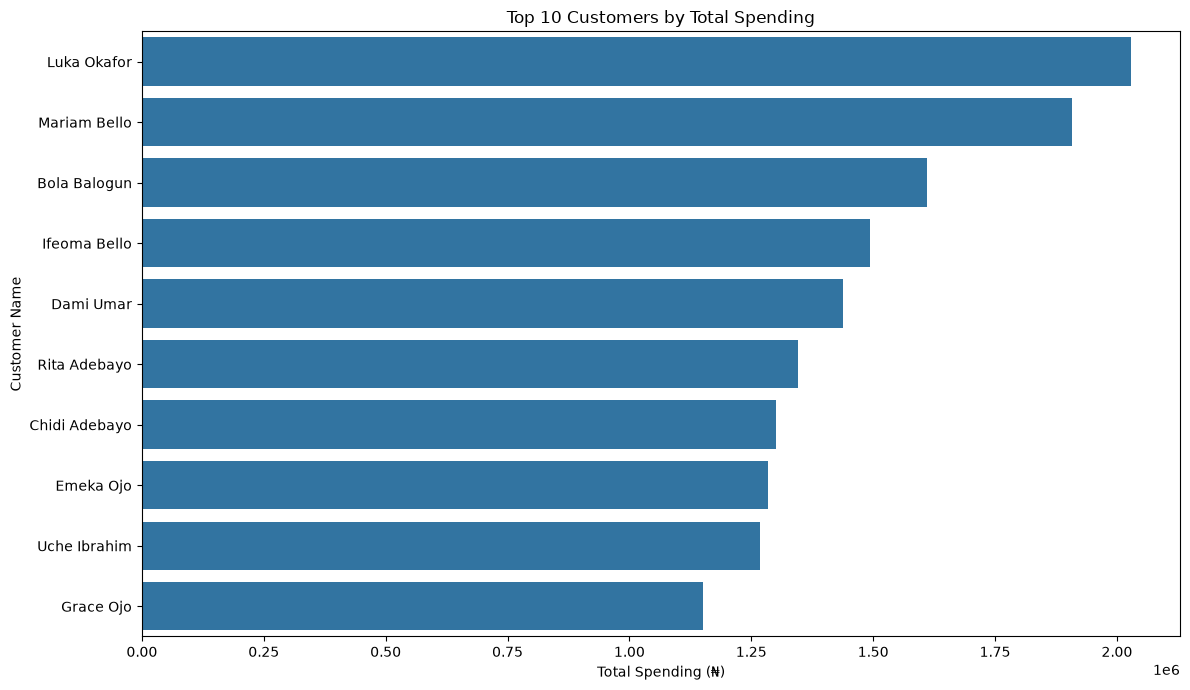

In [6]:
# Top 10 customers
# Calculate customer spending
top_customers = (
    sales.groupby("Customer_Name")["Sales_NGN"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

print(top_customers)

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_customers,
    x="Sales_NGN",
    y="Customer_Name"
)

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Total Spending (₦)")
plt.ylabel("Customer Name")
plt.tight_layout()
plt.show()

          Region  Sales_NGN
0     South West   24386970
1  North Central   20140900
2    South South   18828260
3     South East   18019390
4     North West   16981630
5     North East    9909635


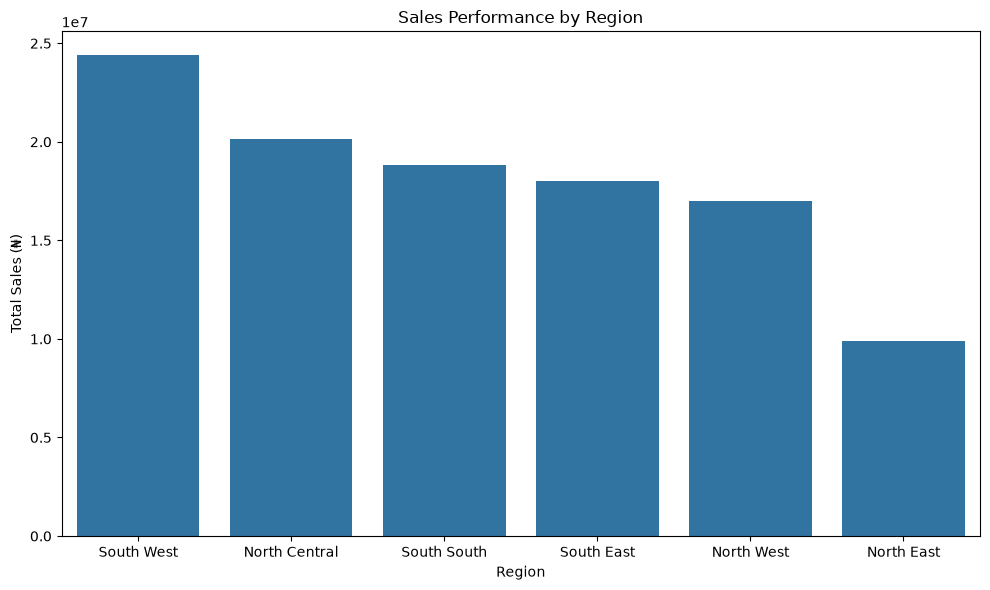

In [7]:
# Which region generate the highest reveune
# Calculate sales by region
region_sales = (
    sales.groupby("Region")["Sales_NGN"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print(region_sales)

# Create bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=region_sales,
    x="Region",
    y="Sales_NGN"
)

plt.title("Sales Performance by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales (₦)")
plt.tight_layout()
plt.show()

    Discount_Group  Total_Sales  Total_Profit  Average_Discount
0      No Discount     40776500    11537345.0               0.0
1     Low Discount     42844785    9953337.55          0.081197
2  Medium Discount     20140200    3546631.63          0.171311
3    High Discount      4210200     498187.48              0.25


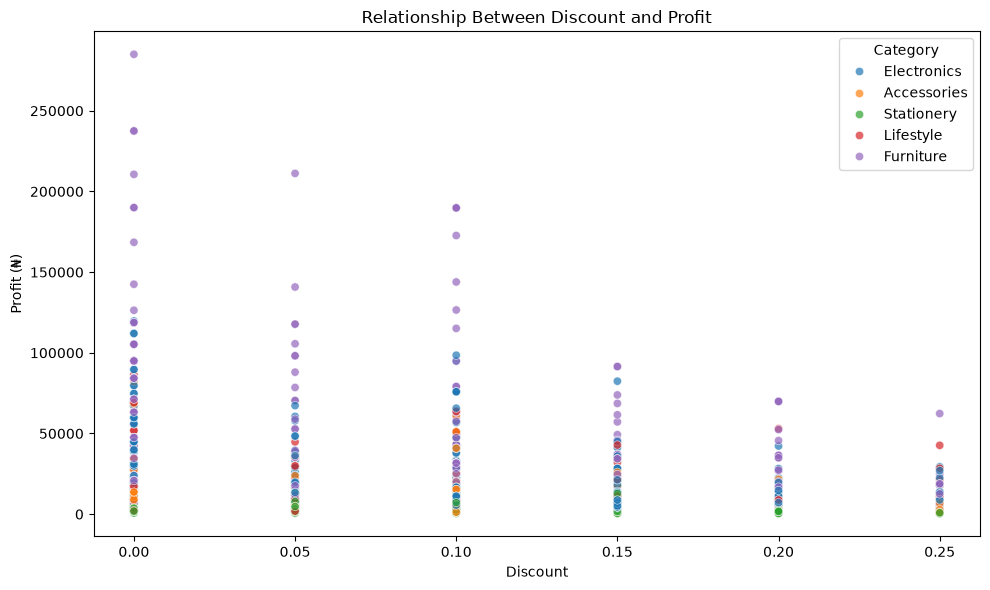

In [8]:
# how does dicount affect sales and profit
# Create discount categories
sales["Discount_Group"] = pd.cut(
    sales["Discount"],
    bins=[-0.001, 0, 0.10, 0.20, 1],
    labels=["No Discount", "Low Discount", "Medium Discount", "High Discount"]
)

# Calculate sales and profit by discount group
discount_analysis = (
    sales.groupby("Discount_Group", observed=False)
    .agg(
        Total_Sales=("Sales_NGN", "sum"),
        Total_Profit=("Profit_NGN", "sum"),
        Average_Discount=("Discount", "mean")
    )
    .reset_index()
)

print(discount_analysis)


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sales,
    x="Discount",
    y="Profit_NGN",
    hue="Category",
    alpha=0.7
)

plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount")
plt.ylabel("Profit (₦)")
plt.tight_layout()
plt.show()